## Project IND320 - Part 2 
Name: Abisan Sagayathasan 

 Github: Abisan-s , direct link: https://github.com/Abisan-s/IND320-reservoir-dashboard


 Streamlit link: https://ind320-reservoir-dashboard-ogxrr3mcdcp4x3bijhecfy.streamlit.app/

 Video link: https://drive.google.com/file/d/1pey9YHQPgwdGkSwuwspmTHu8mmL6xq7a/view?usp=sharing
 

In [1]:
#cheks if the connection to cassandra works
from cassandra.cluster import Cluster

cluster = Cluster(["127.0.0.1"], port=9042)
session = cluster.connect()

print("Connected to Cassandra!")

Connected to Cassandra!


In [2]:
#creates a keyspace for testing the spark to cassandra connection
session.execute("""
CREATE KEYSPACE IF NOT EXISTS my_first_keyspace
WITH REPLICATION = {
    'class': 'SimpleStrategy',
    'replication_factor': 1
};
""")

session.set_keyspace("my_first_keyspace")

#creates a simple test table
session.execute("""
CREATE TABLE IF NOT EXISTS table_with_uuid (
    id timeuuid PRIMARY KEY,
    company text,
    model text,
    price float
);
""")

#some test data
session.execute("""
INSERT INTO table_with_uuid (id, company, model, price)
VALUES (now(), 'Tesla', 'Model S', 20000.0);
""")

session.execute("""
INSERT INTO table_with_uuid (id, company, model, price)
VALUES (now(), 'Polestar', '3', 45000.0);
""")

print("Test data inserted into Cassandra")

Test data inserted into Cassandra


In [3]:
#checks if the spark connection works and that the version is correct
import os
import sys

os.environ["HADOOP_HOME"] = "C:/Hadoop/hadoop-3.3.1"
os.environ["PYSPARK_HADOOP_VERSION"] = "without"

#makes spark use the same environment as the notebook
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("SparkCassandraApp") \
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    ) \
    .config("spark.cassandra.connection.host", "localhost") \
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions"
    ) \
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog"
    ) \
    .config("spark.cassandra.connection.port", "9042") \
    .getOrCreate()

print("Spark version:", spark.version)
print("Notebook Python:", sys.executable)
print("Spark Python:", spark.sparkContext.pythonExec)


Spark version: 3.5.1
Notebook Python: c:\Users\abisa\Desktop\IND320\.venv310\Scripts\python.exe
Spark Python: c:\Users\abisa\Desktop\IND320\.venv310\Scripts\python.exe


In [4]:
#read the cassandra table with spark
test_df = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="table_with_uuid",
        keyspace="my_first_keyspace"
    ) \
    .load()

test_df.show()

+--------------------+--------+-------+-------+
|                  id| company|  model|  price|
+--------------------+--------+-------+-------+
|25374640-ce24-11f...|Polestar|      3|45000.0|
|cc675fa0-ce23-11f...|Polestar|      3|45000.0|
|4d550350-cc90-11f...|Polestar|      3|45000.0|
|25357180-ce24-11f...|   Tesla|Model S|20000.0|
|4d4ced00-cc90-11f...|   Tesla|Model S|20000.0|
|cc62cbc0-ce23-11f...|   Tesla|Model S|20000.0|
|a384f280-cc13-11f...|Polestar|      3|45000.0|
|a37fe970-cc13-11f...|   Tesla|Model S|20000.0|
+--------------------+--------+-------+-------+



In [5]:
#this part checks if python and mongodb can communicate
import os
from dotenv import load_dotenv
from pymongo import MongoClient

#load mongodb uri from env
load_dotenv(override=True)

mongo_uri = os.getenv("MONGODB_URI")

#connect it to mongodb
client = MongoClient(mongo_uri)
db = client["ind320"]
collection = db["test"]

collection.insert_one({"message": "MongoDB connection works"})

print(collection.find_one())

{'_id': ObjectId('6ad6ac8597d76ae16da3231d'), 'message': 'MongoDB connection works'}


## Reservoirstatistic API
- Here we get the API from Swagger UI (statistics from NVE)

In [6]:
import requests
import pandas as pd

url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=30)
response.raise_for_status()

reservoir_data = response.json()

df = pd.DataFrame(reservoir_data)

df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


As we can see this is exact as the same as the csv file from part1

In [7]:
#renaming to the same english names used in part 1
df = df.rename(columns={
    "dato_Id": "date",
    "omrType": "area_type",
    "omrnr": "area_number",
    "iso_aar": "year",
    "iso_uke": "week",
    "fyllingsgrad": "fill_level",
    "kapasitet_TWh": "capacity_TWh",
    "fylling_TWh": "stored_energy_TWh",
    "neste_Publiseringsdato": "next_publication_date",
    "fyllingsgrad_forrige_uke": "fill_level_previous_week",
    "endring_fyllingsgrad": "change_in_fill_level"
})

# convert dates
df["date"] = pd.to_datetime(df["date"])
df["next_publication_date"] = pd.to_datetime(
    df["next_publication_date"],
    errors="coerce"
)

# sort chronologically
df = df.sort_values("date")

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14931 entries, 7282 to 14930
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   date                      14931 non-null  datetime64[ns]
 1   area_type                 14931 non-null  object        
 2   area_number               14931 non-null  int64         
 3   year                      14931 non-null  int64         
 4   week                      14931 non-null  int64         
 5   fill_level                14931 non-null  float64       
 6   capacity_TWh              14931 non-null  float64       
 7   stored_energy_TWh         14931 non-null  float64       
 8   next_publication_date     3609 non-null   datetime64[ns]
 9   fill_level_previous_week  14931 non-null  float64       
 10  change_in_fill_level      14931 non-null  float64       
dtypes: datetime64[ns](2), float64(5), int64(3), object(1)
memory usage: 1.4+ MB


C:\Users\abisa\AppData\Local\Temp\ipykernel_3420\2428006895.py:18: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["next_publication_date"] = pd.to_datetime(


In [8]:
#visually see if the names got changed and the values got sorted
df.head()

,date,area_type,area_number,year,week,fill_level,capacity_TWh,stored_energy_TWh,next_publication_date,fill_level_previous_week,change_in_fill_level
7282,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,NaT,0.777604,-0.146657
4579,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,NaT,0.596027,0.006349
3014,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,NaT,0.801348,-0.242484
9683,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,NaT,0.752631,-0.144643
7882,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869


In [9]:
#the user must be able to choose between the different areas. here i get the area API.
areas_url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOmråder"

areas_response = requests.get(areas_url, timeout=30)
areas_response.raise_for_status()

areas = areas_response.json()

areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

From the HentOmråde API we get information about the areas and their structure. Now we can clean up and make the data easier to understand and work with

In [10]:
#make the area information easier to work with later 
area_rows = []

for group_name, group_list in areas[0].items():
    for area in group_list:
        area_rows.append({
            "group": group_name,
            "name": area["navn"],
            "long_name": area["navn_langt"],
            "area_type": area["omrType"],
            "area_number": area["omrnr"]
        })

areas_df = pd.DataFrame(area_rows)

areas_df

,group,name,long_name,area_type,area_number
0,land,Norge,Norge,NO,0
1,elspot,NO 1,Elspotområde 1,EL,1
2,elspot,NO 2,Elspotområde 2,EL,2
3,elspot,NO 3,Elspotområde 3,EL,3
4,elspot,NO 4,Elspotområde 4,EL,4
5,elspot,NO 5,Elspotområde 5,EL,5
6,vassdrag,VASS1,Vassdragsområde 1,VASS,1
7,vassdrag,VASS2,Vassdragsområde 2,VASS,2
8,vassdrag,VASS3,Vassdragsområde 3,VASS,3
9,vassdrag,VASS4,Vassdragsområde 4,VASS,4


## Plots with API-data
- In this part i am going to recreate the plots in part 1, but with API-data rather than csv

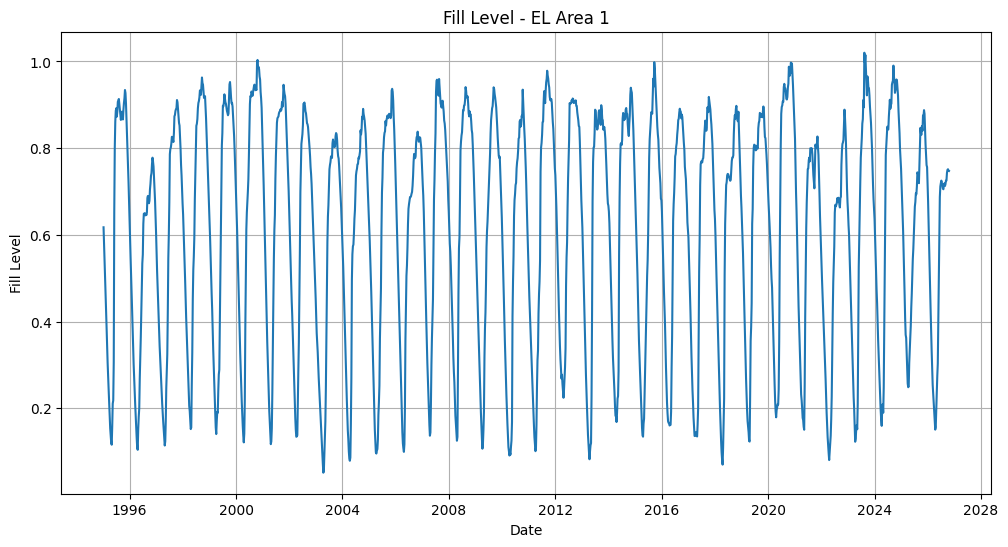

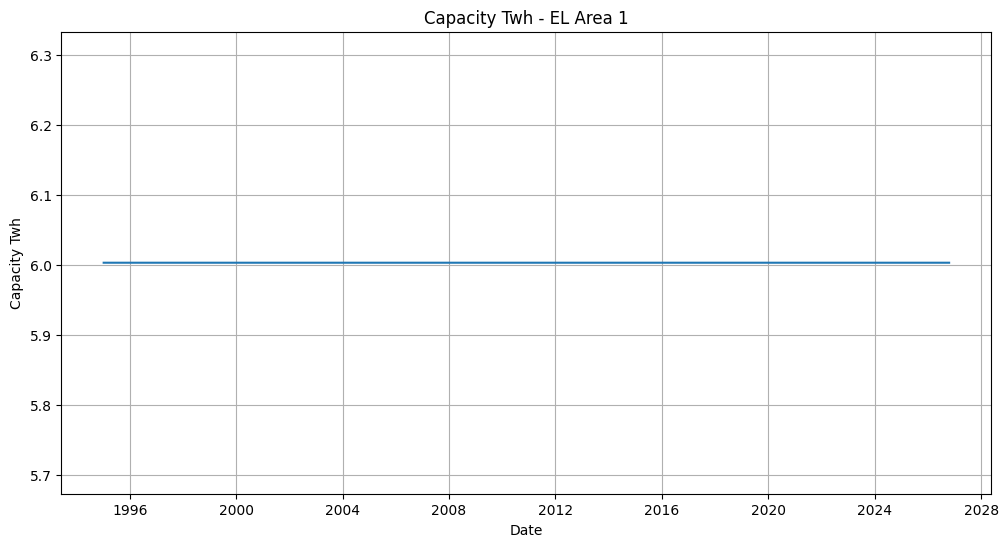

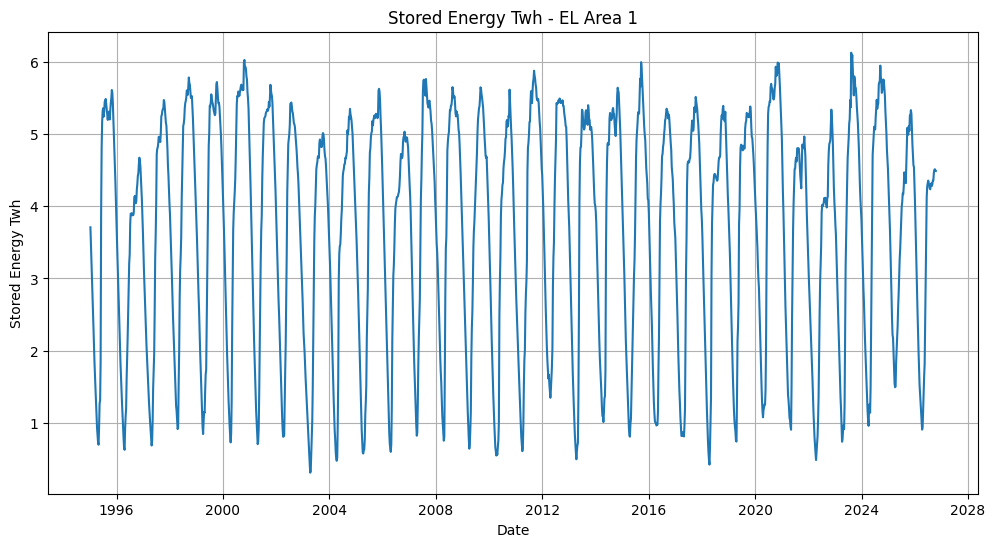

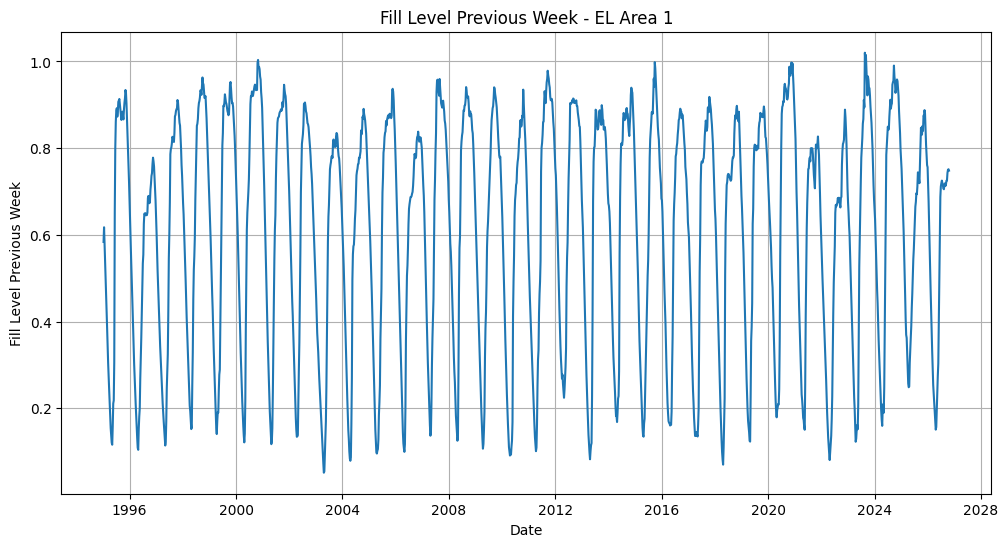

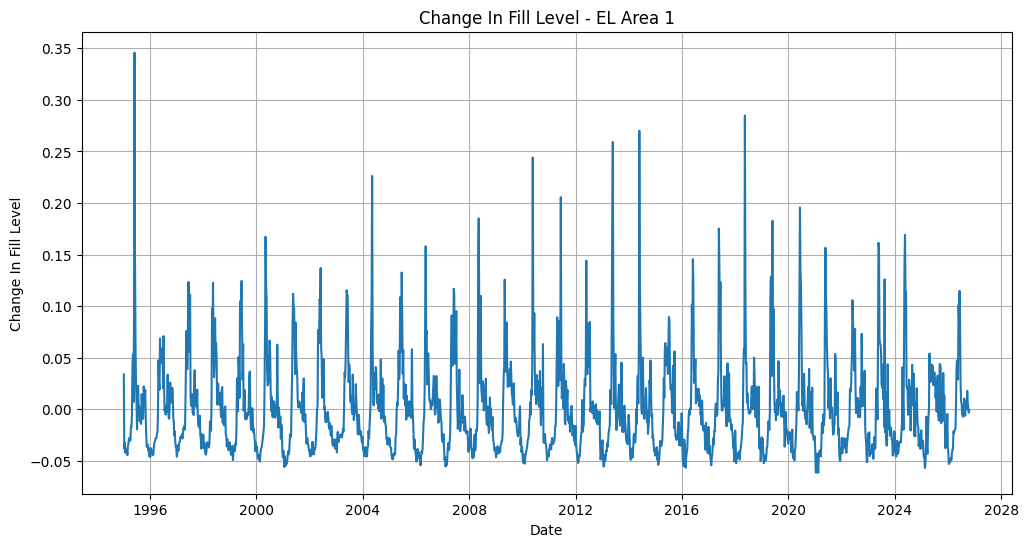

In [11]:
#this part makes a plot each for the fill level, capacity in TWh, the stored energy in TWh, the previous weeks fill level and the change in fill level
import matplotlib.pyplot as plt

plot_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

area_data = df[
    (df["area_type"] == "EL") &
    (df["area_number"] == 1)
].copy()

for column in plot_columns:
    plt.figure(figsize=(12, 6))

    plt.plot(
        area_data["date"],
        area_data[column]
    )

    plt.title(
        f"{column.replace('_', ' ').title()} - EL Area 1"
    )
    plt.xlabel("Date")
    plt.ylabel(column.replace("_", " ").title())
    plt.grid(True)

    plt.show()

As we can see the plots have sucessfully been created with API-data. Now we can make a normalized plot to combine these datas. 

capacity_TWh is constant and is not included in the normalized plot.


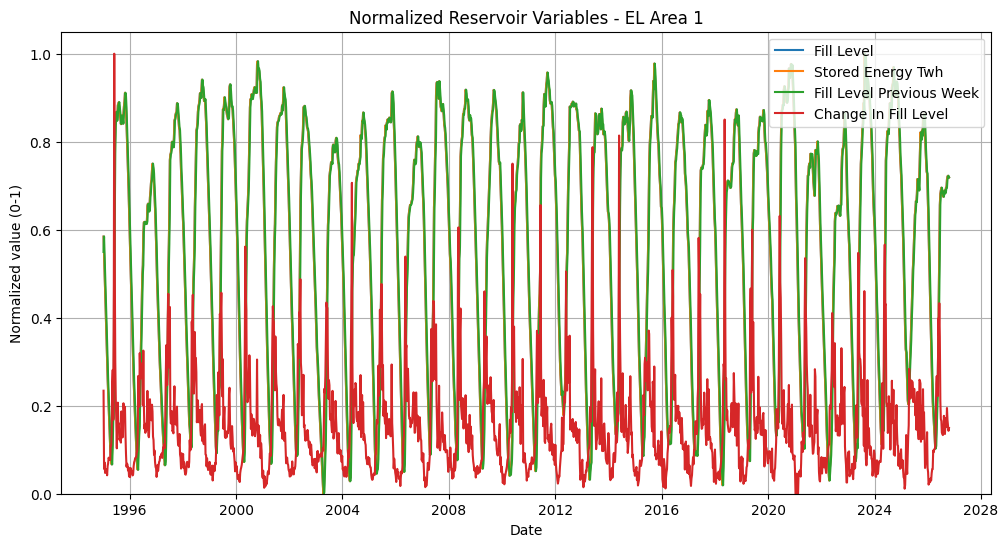

In [12]:
#variables we want to compare
plot_columns = [
    "fill_level",
    "capacity_TWh",
    "stored_energy_TWh",
    "fill_level_previous_week",
    "change_in_fill_level"
]

normalized_data = area_data[plot_columns].copy()

columns_to_plot = []

for column in plot_columns:
    minimum = normalized_data[column].min()
    maximum = normalized_data[column].max()

    #this part only normalizs the variables that change over time
    if maximum != minimum:
        normalized_data[column] = (
            normalized_data[column] - minimum
        ) / (maximum - minimum)

        columns_to_plot.append(column)
    else:
        print(f"{column} is constant and is not included in the normalized plot.") #capacity TWh is always the same, so its not necassary to include it here

plt.figure(figsize=(12, 6))

for column in columns_to_plot:
    plt.plot(
        area_data["date"],
        normalized_data[column],
        label=column.replace("_", " ").title()
    )

plt.title("Normalized Reservoir Variables - EL Area 1")
plt.xlabel("Date")
plt.ylabel("Normalized value (0-1)")
plt.ylim(0, 1.05)
plt.legend(loc="upper right")
plt.grid(True)

plt.show()

As we can see the variables were normalized successfully with API-data. They are normalized between 0 and 1 to make them easier to compare. Capacity is excluded because it is constant for this area. Fill level, stored energy and previous week fill level follow similar seasonal patterns, while change in fill level shows shorter-term weekly variations.

## ENTSO-E API 
- The ENTSO-E API is used to retrieve cross-border electricity transfer data to and from Norway for the project period.

In [13]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

#gets the entsoe token from the .env file
entsoe_token = os.getenv("ENTSOE_TOKEN")

#this part checks if the token is available or not
if entsoe_token:
    print("ENTSO-E token loaded")
else:
    print("ENTSO-E token not available")

ENTSO-E token loaded


In [14]:
import requests
import xml.etree.ElementTree as ET
import pandas as pd
import time


def get_entsoe_flow(in_domain, out_domain, start, end):

    url = "https://web-api.tp.entsoe.eu/api"

    params = {
        "securityToken": entsoe_token,
        "documentType": "A11",
        "in_Domain": in_domain,
        "out_Domain": out_domain,
        "periodStart": start,
        "periodEnd": end
    }

    #try the request up to 3 times. can be changed, but 3 times is good enough
    for attempt in range(3):

        try:
            response = requests.get(
                url,
                params=params,
                timeout=90
            )

            response.raise_for_status()
            break

        except requests.exceptions.RequestException as error:

            print(
                f"Request failed, attempt {attempt + 1}/3:",
                error
            )

            #wait a little before trying again
            time.sleep(5)

    else:
        # if all attempts fail, return an empty dataframe
        print(
            f"Could not get data for "
            f"{in_domain} -> {out_domain}, "
            f"{start} to {end}"
        )

        return pd.DataFrame()


    root = ET.fromstring(response.text)

    namespace = {
        "ns": "urn:iec62325.351:tc57wg16:451-3:publicationdocument:7:0"
    }

    rows = []

    for timeseries in root.findall("ns:TimeSeries", namespace):

        for period in timeseries.findall("ns:Period", namespace):

            start_text = period.find(
                "ns:timeInterval/ns:start",
                namespace
            ).text

            start_time = pd.to_datetime(start_text)

            resolution = period.find(
                "ns:resolution",
                namespace
            ).text

            if resolution == "PT15M":
                step = pd.Timedelta(minutes=15)

            elif resolution == "PT30M":
                step = pd.Timedelta(minutes=30)

            else:
                step = pd.Timedelta(hours=1)

            for point in period.findall("ns:Point", namespace):

                position = int(
                    point.find(
                        "ns:position",
                        namespace
                    ).text
                )

                quantity = float(
                    point.find(
                        "ns:quantity",
                        namespace
                    ).text
                )

                timestamp = start_time + (
                    step * (position - 1)
                )

                rows.append({
                    "datetime": timestamp,
                    "flow_MW": quantity
                })

    return pd.DataFrame(rows)

In [15]:
#connections that will be used for the entsoe api.
connections = {
    "Norway - Sweden": {
        "norway_domain": "10YNO-1--------2",      
        "other_domain": "10Y1001A1001A46L"       
    },

    "Norway - Denmark": {
        "norway_domain": "10YNO-2--------T",      
        "other_domain": "10YDK-1--------W"        
    },

    "Norway - Germany": {
        "norway_domain": "10YNO-2--------T",      
        "other_domain": "10Y1001A1001A82H"        
    }
}

In [20]:
#start date for the two-year period
start_date = pd.Timestamp("2025-01-01", tz="UTC")

#current time
now = pd.Timestamp.now(tz="UTC")

#creates one start date for every month
month_starts = pd.date_range(
    start=start_date,
    end=now.normalize(),
    freq="MS"
)

month_starts

DatetimeIndex(['2025-01-01 00:00:00+00:00', '2025-02-01 00:00:00+00:00',
               '2025-03-01 00:00:00+00:00', '2025-04-01 00:00:00+00:00',
               '2025-05-01 00:00:00+00:00', '2025-06-01 00:00:00+00:00',
               '2025-07-01 00:00:00+00:00', '2025-08-01 00:00:00+00:00',
               '2025-09-01 00:00:00+00:00', '2025-10-01 00:00:00+00:00',
               '2025-11-01 00:00:00+00:00', '2025-12-01 00:00:00+00:00',
               '2026-01-01 00:00:00+00:00', '2026-02-01 00:00:00+00:00',
               '2026-03-01 00:00:00+00:00', '2026-04-01 00:00:00+00:00',
               '2026-05-01 00:00:00+00:00', '2026-06-01 00:00:00+00:00',
               '2026-07-01 00:00:00+00:00', '2026-08-01 00:00:00+00:00',
               '2026-09-01 00:00:00+00:00', '2026-10-01 00:00:00+00:00'],
              dtype='datetime64[ns, UTC]', freq='MS')

In [21]:
all_entsoe_data = []

for connection_name, domains in connections.items():

    for month_start in month_starts:

        month_end = month_start + pd.offsets.MonthBegin(1)

        #prevents requests for future dates
        if month_end > now:
            month_end = now.floor("h")

        period_start = month_start.strftime("%Y%m%d%H%M")
        period_end = month_end.strftime("%Y%m%d%H%M")

        #out of norway
        df_out = get_entsoe_flow(
            domains["norway_domain"],
            domains["other_domain"],
            period_start,
            period_end
        )

        if not df_out.empty:
            df_out["connection"] = connection_name
            df_out["direction"] = "Out of Norway"

            all_entsoe_data.append(df_out)

        #into norway
        df_in = get_entsoe_flow(
            domains["other_domain"],
            domains["norway_domain"],
            period_start,
            period_end
        )

        if not df_in.empty:
            df_in["connection"] = connection_name
            df_in["direction"] = "Into Norway"

            all_entsoe_data.append(df_in)

In [22]:
#combine all downloaded ENTSO-E data into one dataframe
entsoe_all_df = pd.concat(
    all_entsoe_data,
    ignore_index=True
)

#sort by connection, direction and time
entsoe_all_df = entsoe_all_df.sort_values(
    ["connection", "direction", "datetime"]
).reset_index(drop=True)

entsoe_all_df.head()

,datetime,flow_MW,connection,direction
0,2025-01-01 00:00:00+00:00,0.00,Norway - Denmark,Into Norway
1,2025-01-02 04:00:00+00:00,6.33,Norway - Denmark,Into Norway
2,2025-01-02 05:00:00+00:00,324.96,Norway - Denmark,Into Norway
3,2025-01-02 06:00:00+00:00,365.33,Norway - Denmark,Into Norway
4,2025-01-02 07:00:00+00:00,831.02,Norway - Denmark,Into Norway


In [23]:
# double check the connections and directions
entsoe_all_df.groupby(
    ["connection", "direction"]
).size()

connection        direction    
Norway - Denmark  Into Norway      39893
                  Out of Norway    18656
Norway - Germany  Into Norway      42311
                  Out of Norway    16409
Norway - Sweden   Into Norway      12195
                  Out of Norway    33515
dtype: int64

In [24]:
# check the time period
print("First date:", entsoe_all_df["datetime"].min())
print("Last date:", entsoe_all_df["datetime"].max())

First date: 2025-01-01 00:00:00+00:00
Last date: 2026-10-22 12:30:00+00:00


## Cassandra 
- 

In [25]:
#double checkong the dates before bullding the table.
print("First date:", entsoe_all_df["datetime"].min())
print("Last date:", entsoe_all_df["datetime"].max())

First date: 2025-01-01 00:00:00+00:00
Last date: 2026-10-22 12:30:00+00:00


In [26]:
# selects the keyspace used for this project
session.set_keyspace("my_first_keyspace")

print("Using keyspace: my_first_keyspace")

Using keyspace: my_first_keyspace


In [27]:
#creates a cassandra table for the entsoe data
session.execute("""
CREATE TABLE IF NOT EXISTS entsoe_transfers (
    datetime timestamp,
    connection text,
    direction text,
    flow_mw double,
    PRIMARY KEY ((connection, direction), datetime)
);
""")

#confirms that the table was created
print("Cassandra table created")

Cassandra table created


In [28]:
#makes a copy of the entsoe data before sending it to spark
entsoe_for_spark = entsoe_all_df.copy()

#removes timezone information so spark can handle it correctly
entsoe_for_spark["datetime"] = (
    entsoe_for_spark["datetime"]
    .dt.tz_convert("UTC")
    .dt.tz_localize(None)
)

#renames the column so it matches the cassandra table
entsoe_for_spark = entsoe_for_spark.rename(
    columns={"flow_MW": "flow_mw"}
)

#quick double check before converting to spark
entsoe_for_spark.head()

,datetime,flow_mw,connection,direction
0,2025-01-01 00:00:00,0.00,Norway - Denmark,Into Norway
1,2025-01-02 04:00:00,6.33,Norway - Denmark,Into Norway
2,2025-01-02 05:00:00,324.96,Norway - Denmark,Into Norway
3,2025-01-02 06:00:00,365.33,Norway - Denmark,Into Norway
4,2025-01-02 07:00:00,831.02,Norway - Denmark,Into Norway


In [29]:
# workaround for PySpark on Python 3.12
import setuptools

print("setuptools loaded")

setuptools loaded


In [30]:
#this part converts the pandas df to a spark df
entsoe_spark_df = spark.createDataFrame(entsoe_for_spark)

#double check that spark understood the column types
entsoe_spark_df.printSchema()

root
 |-- datetime: timestamp (nullable = true)
 |-- flow_mw: double (nullable = true)
 |-- connection: string (nullable = true)
 |-- direction: string (nullable = true)



In [31]:
import sys
print(sys.version)

3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]


In [32]:
#writes the spark df into the cassandra table
entsoe_spark_df.write \
    .format("org.apache.spark.sql.cassandra") \
    .mode("append") \
    .options(
        table="entsoe_transfers",
        keyspace="my_first_keyspace"
    ) \
    .save()

print("ENTSO-E data inserted into Cassandra using Spark")

ENTSO-E data inserted into Cassandra using Spark


In [33]:
#reads the entsoe table back from cassandra using spark
cassandra_entsoe_df = spark.read \
    .format("org.apache.spark.sql.cassandra") \
    .options(
        table="entsoe_transfers",
        keyspace="my_first_keyspace"
    ) \
    .load()

#double check that the data exists in cassandra
cassandra_entsoe_df.show(5)

+---------------+-----------+-------------------+-------+
|     connection|  direction|           datetime|flow_mw|
+---------------+-----------+-------------------+-------+
|Norway - Sweden|Into Norway|2025-01-01 00:00:00|    0.0|
|Norway - Sweden|Into Norway|2025-01-02 12:00:00| 266.63|
|Norway - Sweden|Into Norway|2025-01-02 13:00:00|  291.3|
|Norway - Sweden|Into Norway|2025-01-02 14:00:00| 411.68|
|Norway - Sweden|Into Norway|2025-01-02 15:00:00|  142.6|
+---------------+-----------+-------------------+-------+
only showing top 5 rows



In [34]:
#extracts the relevant columns from cassandra using spark
spark_extracted_df = cassandra_entsoe_df.select(
    "datetime",
    "connection",
    "direction",
    "flow_mw"
)

#checks the extracted data
spark_extracted_df.show(5)

+-------------------+----------------+-----------+-------+
|           datetime|      connection|  direction|flow_mw|
+-------------------+----------------+-----------+-------+
|2025-01-01 00:00:00|Norway - Denmark|Into Norway|    0.0|
|2025-01-02 04:00:00|Norway - Denmark|Into Norway|   6.33|
|2025-01-02 05:00:00|Norway - Denmark|Into Norway| 324.96|
|2025-01-02 06:00:00|Norway - Denmark|Into Norway| 365.33|
|2025-01-02 07:00:00|Norway - Denmark|Into Norway| 831.02|
+-------------------+----------------+-----------+-------+
only showing top 5 rows



In [35]:
#checks the number of rows after the Spark extraction
print("Number of rows:", spark_extracted_df.count())

Number of rows: 162965


In [36]:
#converts the spark data to pandas for plotting
plot_df = spark_extracted_df.toPandas()

#makes sure datetime is in the correct format
plot_df["datetime"] = pd.to_datetime(plot_df["datetime"])

plot_df.head()

,datetime,connection,direction,flow_mw
0,2025-01-01 00:00:00,Norway - Denmark,Into Norway,0.00
1,2025-01-02 04:00:00,Norway - Denmark,Into Norway,6.33
2,2025-01-02 05:00:00,Norway - Denmark,Into Norway,324.96
3,2025-01-02 06:00:00,Norway - Denmark,Into Norway,365.33
4,2025-01-02 07:00:00,Norway - Denmark,Into Norway,831.02


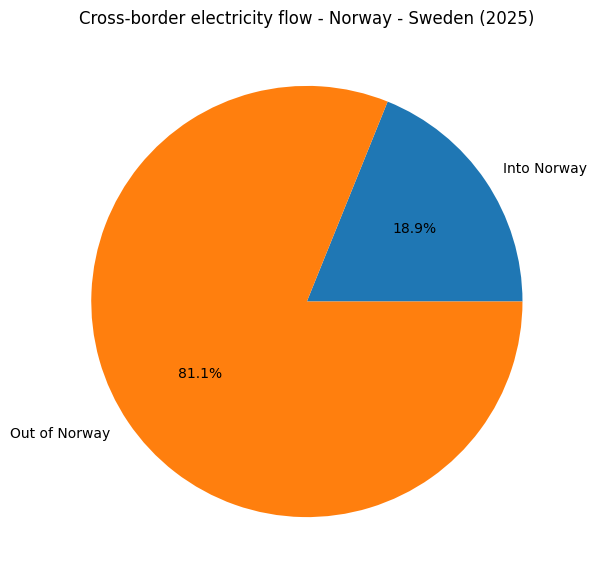

In [37]:
import matplotlib.pyplot as plt

#choose one connection and one year for the pie chart
selected_connection = "Norway - Sweden"
selected_year = 2025

#filters the data to the selected connection and year
pie_data = plot_df[
    (plot_df["connection"] == selected_connection) &
    (plot_df["datetime"].dt.year == selected_year)
].copy()

#sums the electricity flow for each direction
pie_summary = (
    pie_data
    .groupby("direction")["flow_mw"]
    .sum()
)

#creates the pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    pie_summary.values,
    labels=pie_summary.index,
    autopct="%1.1f%%"
)

plt.title(
    f"Cross-border electricity flow - {selected_connection} ({selected_year})"
)

plt.show()

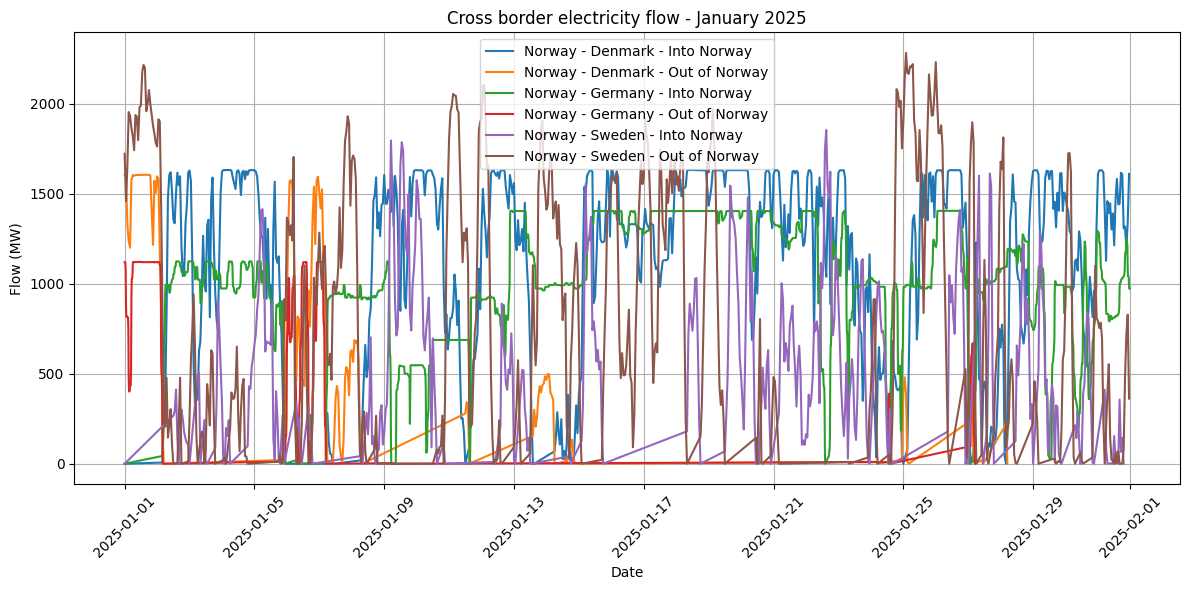

In [44]:
#choose the year for the line plot
selected_year = 2025

#filters the data to January in the selected year
line_data = plot_df[
    (plot_df["datetime"].dt.year == selected_year) &
    (plot_df["datetime"].dt.month == 1)
].copy()

#creates one line for each connection and direction
plt.figure(figsize=(12, 6))

for (connection, direction), group in line_data.groupby(
    ["connection", "direction"]
):
    group = group.sort_values("datetime")

    plt.plot(
        group["datetime"],
        group["flow_mw"],
        label=f"{connection} - {direction}"
    )

plt.title(
    f"Cross border electricity flow - January {selected_year}"
)

plt.xlabel("Date")
plt.ylabel("Flow (MW)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [45]:
from pymongo import MongoClient
import os
from dotenv import load_dotenv

load_dotenv(override=True)

#connects to mongodb
mongo_uri = os.getenv("MONGODB_URI")
client = MongoClient(mongo_uri)

db = client["ind320"]
collection = db["entsoe_transfers"]

#converts the spark extracted data to pandas before sending to mongodb
mongo_df = spark_extracted_df.toPandas()

#makes datetime compatible with mongodb
mongo_df["datetime"] = pd.to_datetime(
    mongo_df["datetime"]
).dt.to_pydatetime()

#converts the dataframe into records
records = mongo_df.to_dict("records")

#removes old data to avoid duplicates
collection.delete_many({})
collection.insert_many(records)

print("ENTSO-E data saved to MongoDB")
print("Number of documents:", collection.count_documents({}))

C:\Users\abisa\AppData\Local\Temp\ipykernel_3420\3763557368.py:20: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  ).dt.to_pydatetime()


ENTSO-E data saved to MongoDB
Number of documents: 162965


## AI Usage
In part 2 of this project i used AI alot on explain and downloading and understanding Docker, Cassandra, MongoDB, Spark and APIs. In the notebook part, writing codes this time was easier because a lot of 
code was removed due to the change from CSV to API. Since a lot of the codes were reused from part 1 this time i used AI only a few times especially in the ENTSOE part. As i did in the first part i also used AI to help me with some of the plots in the notebook part. 

In the streamlit part of the task i used AI more frequently to visualise, explain and see how the plots, sliders, pills and so on looked like and how they worked together with each other. It all worked out more smoother in the streamlit part because all the time consuming parts were done in the notebook part. 

## Log 
This is the second part of the assignment. I started this project by first understanding the different parts as docker, mongodb, spark and so on because i personally find these subjects very interesting. I then started downloading and set up docker and cassandra, which took some time because there were some issues with the installment part, but after some time it worked out. MongoDB was very easy to understand and i had some issues with spark, but fter changing the pyspark version and configuring hadoop, spark worked together with cassandra.

With the entsoe part i did a clumsy mistake by writing the wrong mail to Entsoe transparency to get access to tokens (sent mail to teacher). This mistake made that i couldnt use tokens and thereby the entsoe page in streamlit is not fully operetable, but as soon as the tokens are granted they wil work because i already made the structure in the entsoe.py part and prepared the entsoe section in the part 2 notebook, so the remaining API functionality can be added when the token becomes available.

Coding wise this part was for me more easier because a lot of code was reused and some code were also removed because of the change from CSV file reading to API-data driven. The reservoir data is now retrieved directly from the NVE magasinstatistikk API. The data is converted into a panda dataframe, renamed to the same english column names used in part 1, and used to recreate the previous visualizations.

The streamlit app was also updated to use the NVE API directly. I added radio buttons for the different area types, updated the plot filtering, and created a new entsoe page using columns, radio buttons, pills and an expander. Even though its not fully operable, its core functions is still working. Mongodb is connected to the streamlit app using treamlit secrets so that login information is not exposed on github. Overall this part gave me more experience with databases, APIs, Spark, Docker and connecting several technologies together in one project. I learned alot and improved my knowledge alot and there is till more to learn!